# Dataset 4 - Fake Job Posting Detection

In [ ]:
# Imports & Dataset Loading
import os
import pandas as pd
import numpy as np

# Read Dataset 4 from Datasets folder
if os.path.exists("../Datasets/Dataset4.csv"):
    df = pd.read_csv("../Datasets/Dataset4.csv")
else:
    df = pd.read_csv("../Datasets/Fake_Job_Posting_Detection_Dataset.csv")
    df.to_csv("../Datasets/Dataset4.csv", index=False)

In [2]:
# Exploratory Data Analysis (EDA)

# Display first 5 rows
df.head()

,Job_Title,Salary_INR,Company_Type,Employment_Type,Label
0,Business Analyst,610820,Recruitment Agency,Internship,Real
1,Software Engineer,1822597,Startup,Internship,Real
2,Web Developer,2475227,Recruitment Agency,Part-time,Real
3,Data Analyst,672554,SME,Part-time,Real
4,Business Analyst,2195998,SME,Contract,Real


In [3]:
# Dataset Size & Dimensions

# Check total rows and columns
print("Dataset Shape:", df.shape)

Dataset Shape: (2000, 5)


In [4]:
# Column Names

# Check all available features
print("Columns in Dataset 4:\n", df.columns.tolist())

Columns in Dataset 4:
 ['Job_Title', 'Salary_INR', 'Company_Type', 'Employment_Type', 'Label']


In [5]:
# Data Information & Types

# Check data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Job_Title        2000 non-null   object
 1   Salary_INR       2000 non-null   int64 
 2   Company_Type     2000 non-null   object
 3   Employment_Type  2000 non-null   object
 4   Label            2000 non-null   object
dtypes: int64(1), object(4)
memory usage: 78.3+ KB


In [6]:
# Check Missing Values

# Count missing values per column
df.isnull().sum()

Job_Title          0
Salary_INR         0
Company_Type       0
Employment_Type    0
Label              0
dtype: int64

In [7]:
# Target Class Distribution

# Check class balance (Real vs Fake)
print("Target Distribution:")
print(df["Label"].value_counts(dropna=False))

# Real = Legitimate jobs (0)
# Fake = Fraudulent jobs (1)

Target Distribution:
Label
Real    1503
Fake     497
Name: count, dtype: int64


## Data Cleaning & Text Feature Combination

In [8]:
# Cleaning Pipeline

# 1. Make a working copy
df_clean = df.copy()

# 2. Convert 'Label' into numeric binary target 'fraudulent' (0 = Real, 1 = Fake)
df_clean['fraudulent'] = df_clean['Label'].map({'Real': 0, 'Fake': 1}).astype(int)

# 3. Combine text features into a single 'text' column
df_clean['text'] = (
    df_clean['Job_Title'].astype(str) + " " +
    df_clean['Company_Type'].astype(str) + " " +
    df_clean['Employment_Type'].astype(str)
)

# 4. Preview combined text
df_clean[['text', 'fraudulent']].head()

,text,fraudulent
0,Business Analyst Recruitment Agency Internship,0
1,Software Engineer Startup Internship,0
2,Web Developer Recruitment Agency Part-time,0
3,Data Analyst SME Part-time,0
4,Business Analyst SME Contract,0


In [9]:
# Save Cleaned Dataset as CSV

# Ensure data directory exists and save
os.makedirs("../data/processed", exist_ok=True)
df_clean.to_csv("../data/processed/cleaned_fake_jobs_dataset4.csv", index=False)
print("✅ Cleaned Dataset 4 saved to data/processed/cleaned_fake_jobs_dataset4.csv")

✅ Cleaned Dataset 4 saved to data/processed/cleaned_fake_jobs_dataset4.csv


## Natural Language Processing (NLP) & Text Preprocessing

In [10]:
# NLTK Setup & Preprocessing Function

import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required NLTK resources
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text)     # Remove punctuation
    tokens = word_tokenize(text)            # Tokenization
    tokens = [word for word in tokens if word not in stop_words]  # Remove stopwords
    tokens = [lemmatizer.lemmatize(word) for word in tokens]      # Lemmatization
    return " ".join(tokens)

In [11]:
# Apply NLP Cleaning

print("⏳ Cleaning text data...")
df_clean["clean_text"] = df_clean["text"].apply(preprocess_text)

# Inspect cleaned text vs original
df_clean[["text", "clean_text", "fraudulent"]].head()

⏳ Cleaning text data...


,text,clean_text,fraudulent
0,Business Analyst Recruitment Agency Internship,business analyst recruitment agency internship,0
1,Software Engineer Startup Internship,software engineer startup internship,0
2,Web Developer Recruitment Agency Part-time,web developer recruitment agency parttime,0
3,Data Analyst SME Part-time,data analyst sme parttime,0
4,Business Analyst SME Contract,business analyst sme contract,0


## Feature Extraction (TF-IDF Vectorization) & Train-Test Split

In [12]:
# TF-IDF Vectorization

from sklearn.feature_extraction.text import TfidfVectorizer

# Vectorize top 5,000 word features
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(df_clean["clean_text"])
y = df_clean["fraudulent"]

print("Feature Matrix X Shape:", X.shape)
print("Target Array y Shape:", y.shape)

Feature Matrix X Shape: (2000, 22)
Target Array y Shape: (2000,)


In [13]:
# Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y       # Preserves class proportions in train & test sets
)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape : {X_test.shape}  | y_test shape : {y_test.shape}")

X_train shape: (1600, 22) | y_train shape: (1600,)
X_test shape : (400, 22)  | y_test shape : (400,)


In [14]:
# Setup to save models and collect metrics

import os
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Ensure save directory exists
os.makedirs("saved_models", exist_ok=True)

# List to collect all comparison metrics
results = []

## 1. Logistic Regression

In [15]:
# 1. Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create & Train
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_lr = lr_model.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))

# Save model artifact
joblib.dump(lr_model, "saved_models/logistic_regression_dataset4.pkl")

# Record for comparison
results.append({
    "Model": "Logistic Regression",
    "Accuracy": round(accuracy_score(y_test, y_pred_lr), 4),
    "Precision": round(precision_score(y_test, y_pred_lr, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_lr, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_lr, zero_division=0), 4)
})

Logistic Regression Accuracy: 0.7525

Classification Report:
               precision    recall  f1-score   support

           0       0.75      1.00      0.86       301
           1       0.00      0.00      0.00        99

    accuracy                           0.75       400
   macro avg       0.38      0.50      0.43       400
weighted avg       0.57      0.75      0.65       400

Confusion Matrix:
 [[301   0]
 [ 99   0]]


c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _war

## 2. Naive Bayes

In [16]:
# 2. Naive Bayes
from sklearn.naive_bayes import MultinomialNB

# Create & Train
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_nb = nb_model.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))

# Save model artifact
joblib.dump(nb_model, "saved_models/naive_bayes_dataset4.pkl")

# Record for comparison
results.append({
    "Model": "Multinomial Naive Bayes",
    "Accuracy": round(accuracy_score(y_test, y_pred_nb), 4),
    "Precision": round(precision_score(y_test, y_pred_nb, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_nb, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_nb, zero_division=0), 4)
})

Naive Bayes Accuracy: 0.7525


c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _war


Classification Report:
               precision    recall  f1-score   support

           0       0.75      1.00      0.86       301
           1       0.00      0.00      0.00        99

    accuracy                           0.75       400
   macro avg       0.38      0.50      0.43       400
weighted avg       0.57      0.75      0.65       400

Confusion Matrix:
 [[301   0]
 [ 99   0]]


## 3. Support Vector Machine (Linear SVC)

In [17]:
# 3. SVM (Support Vector Machine)
from sklearn.svm import LinearSVC

# Create & Train
svm_model = LinearSVC(random_state=42)
svm_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_svm = svm_model.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))

# Save model artifact
joblib.dump(svm_model, "saved_models/svm_dataset4.pkl")

# Record for comparison
results.append({
    "Model": "SVM (Linear)",
    "Accuracy": round(accuracy_score(y_test, y_pred_svm), 4),
    "Precision": round(precision_score(y_test, y_pred_svm, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_svm, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_svm, zero_division=0), 4)
})

SVM Accuracy: 0.7525

Classification Report:
               precision    recall  f1-score   support

           0       0.75      1.00      0.86       301
           1       0.00      0.00      0.00        99

    accuracy                           0.75       400
   macro avg       0.38      0.50      0.43       400
weighted avg       0.57      0.75      0.65       400

Confusion Matrix:
 [[301   0]
 [ 99   0]]


c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _war

## 4. K-Nearest Neighbors (KNN)

In [18]:
# 4. KNN (K-Nearest Neighbors)
from sklearn.neighbors import KNeighborsClassifier

# Create & Train
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_knn = knn_model.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print("\nClassification Report:\n", classification_report(y_test, y_pred_knn))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))

# Save model artifact
joblib.dump(knn_model, "saved_models/knn_dataset4.pkl")

# Record for comparison
results.append({
    "Model": "KNN",
    "Accuracy": round(accuracy_score(y_test, y_pred_knn), 4),
    "Precision": round(precision_score(y_test, y_pred_knn, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_knn, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_knn, zero_division=0), 4)
})

KNN Accuracy: 0.7225

Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.92      0.83       301
           1       0.34      0.13      0.19        99

    accuracy                           0.72       400
   macro avg       0.55      0.52      0.51       400
weighted avg       0.66      0.72      0.67       400

Confusion Matrix:
 [[276  25]
 [ 86  13]]


## 5. Decision Tree

In [19]:
# 5. Decision Tree
from sklearn.tree import DecisionTreeClassifier

# Create & Train
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))

# Save model artifact
joblib.dump(dt_model, "saved_models/decision_tree_dataset4.pkl")

# Record for comparison
results.append({
    "Model": "Decision Tree",
    "Accuracy": round(accuracy_score(y_test, y_pred_dt), 4),
    "Precision": round(precision_score(y_test, y_pred_dt, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_dt, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_dt, zero_division=0), 4)
})

Decision Tree Accuracy: 0.7325

Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.96      0.84       301
           1       0.25      0.04      0.07        99

    accuracy                           0.73       400
   macro avg       0.50      0.50      0.46       400
weighted avg       0.63      0.73      0.65       400

Confusion Matrix:
 [[289  12]
 [ 95   4]]


## 6. Random Forest

In [20]:
# 6. Random Forest
from sklearn.ensemble import RandomForestClassifier

# Create & Train
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

# Save model artifact
joblib.dump(rf_model, "saved_models/random_forest_dataset4.pkl")

# Record for comparison
results.append({
    "Model": "Random Forest",
    "Accuracy": round(accuracy_score(y_test, y_pred_rf), 4),
    "Precision": round(precision_score(y_test, y_pred_rf, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_rf, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_rf, zero_division=0), 4)
})

Random Forest Accuracy: 0.7325

Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.95      0.84       301
           1       0.30      0.06      0.10        99

    accuracy                           0.73       400
   macro avg       0.53      0.51      0.47       400
weighted avg       0.64      0.73      0.66       400

Confusion Matrix:
 [[287  14]
 [ 93   6]]


## 7. Gradient Boosting

In [21]:
# 7. Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

# Create & Train
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting Accuracy:", accuracy_score(y_test, y_pred_gb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_gb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_gb))

# Save model artifact
joblib.dump(gb_model, "saved_models/gradient_boosting_dataset4.pkl")

# Record for comparison
results.append({
    "Model": "Gradient Boosting",
    "Accuracy": round(accuracy_score(y_test, y_pred_gb), 4),
    "Precision": round(precision_score(y_test, y_pred_gb, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_gb, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_gb, zero_division=0), 4)
})

Gradient Boosting Accuracy: 0.7425

Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.97      0.85       301
           1       0.33      0.04      0.07        99

    accuracy                           0.74       400
   macro avg       0.54      0.51      0.46       400
weighted avg       0.65      0.74      0.66       400

Confusion Matrix:
 [[293   8]
 [ 95   4]]


## 8. AdaBoost Classifier

In [22]:
# 8. AdaBoost Classifier
from sklearn.ensemble import AdaBoostClassifier

# Create & Train
ada_model = AdaBoostClassifier(n_estimators=100, random_state=42)
ada_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_ada = ada_model.predict(X_test)

print("AdaBoost Accuracy:", accuracy_score(y_test, y_pred_ada))
print("\nClassification Report:\n", classification_report(y_test, y_pred_ada))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ada))

# Save model artifact
joblib.dump(ada_model, "saved_models/adaboost_dataset4.pkl")

# Record for comparison
results.append({
    "Model": "AdaBoost",
    "Accuracy": round(accuracy_score(y_test, y_pred_ada), 4),
    "Precision": round(precision_score(y_test, y_pred_ada, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_ada, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_ada, zero_division=0), 4)
})

AdaBoost Accuracy: 0.7525

Classification Report:
               precision    recall  f1-score   support

           0       0.75      1.00      0.86       301
           1       0.00      0.00      0.00        99

    accuracy                           0.75       400
   macro avg       0.38      0.50      0.43       400
weighted avg       0.57      0.75      0.65       400

Confusion Matrix:
 [[301   0]
 [ 99   0]]


c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _war

## 9. XGBoost

In [23]:
# 9. XGBoost
from xgboost import XGBClassifier

# Create & Train
xgb_model = XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=42)
xgb_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))

# Save model artifact
joblib.dump(xgb_model, "saved_models/xgboost_dataset4.pkl")

# Record for comparison
results.append({
    "Model": "XGBoost",
    "Accuracy": round(accuracy_score(y_test, y_pred_xgb), 4),
    "Precision": round(precision_score(y_test, y_pred_xgb, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_xgb, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_xgb, zero_division=0), 4)
})

XGBoost Accuracy: 0.73

Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.95      0.84       301
           1       0.26      0.05      0.08        99

    accuracy                           0.73       400
   macro avg       0.51      0.50      0.46       400
weighted avg       0.63      0.73      0.65       400

Confusion Matrix:
 [[287  14]
 [ 94   5]]


## 10. Model Comparison Table & Visual Bar Chart


--- Dataset 4: 9 Models Performance Comparison ---


,Model,Accuracy,Precision,Recall,F1-Score
0,KNN,0.7225,0.3421,0.1313,0.1898
1,Random Forest,0.7325,0.3000,0.0606,0.1008
2,XGBoost,0.7300,0.2632,0.0505,0.0847
3,Gradient Boosting,0.7425,0.3333,0.0404,0.0721
4,Decision Tree,0.7325,0.2500,0.0404,0.0696
5,Logistic Regression,0.7525,0.0000,0.0000,0.0000
6,Multinomial Naive Bayes,0.7525,0.0000,0.0000,0.0000
7,SVM (Linear),0.7525,0.0000,0.0000,0.0000
8,AdaBoost,0.7525,0.0000,0.0000,0.0000


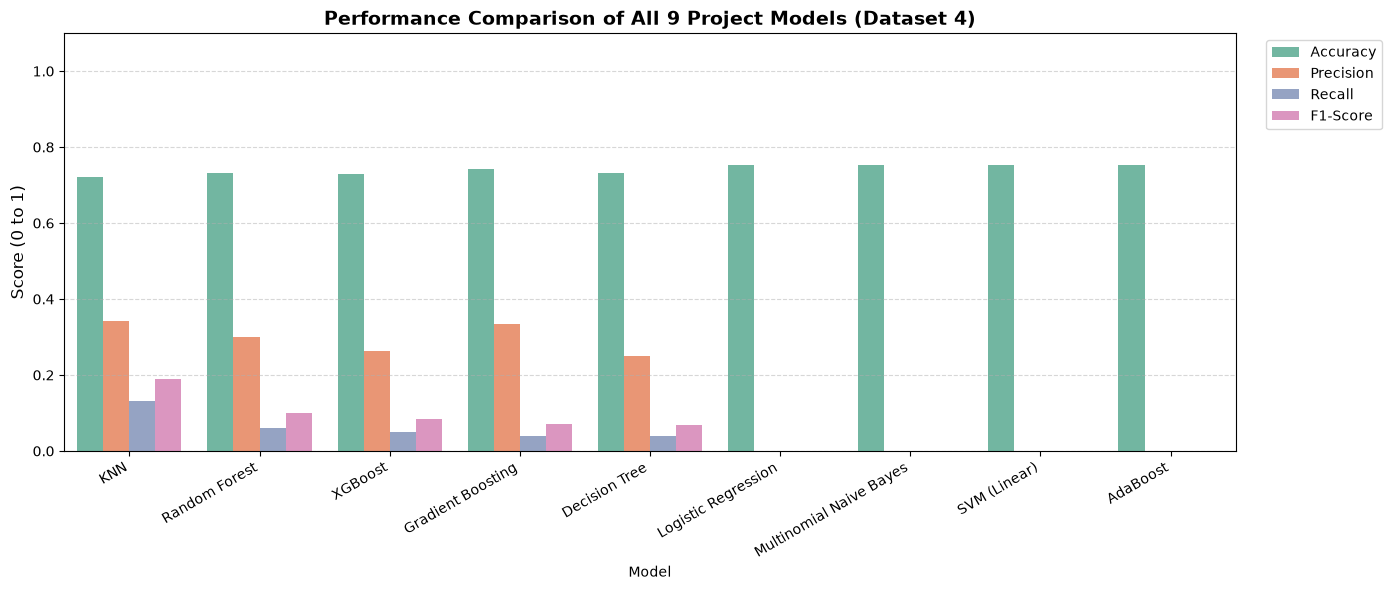

🏆 Best Performing Model on Dataset 4 is: KNN


In [24]:
# Comparison Summary Table
comparison_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
print("\n--- Dataset 4: 9 Models Performance Comparison ---")
display(comparison_df)

# Save the TF-IDF Vectorizer
joblib.dump(tfidf, "saved_models/tfidf_vectorizer_dataset4.pkl")

# Comparison Bar Chart
plt.figure(figsize=(14, 6))
df_melted = comparison_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

sns.barplot(data=df_melted, x="Model", y="Score", hue="Metric", palette="Set2")
plt.title("Performance Comparison of All 9 Project Models (Dataset 4)", fontsize=14, fontweight='bold')
plt.ylabel("Score (0 to 1)", fontsize=12)
plt.ylim(0.0, 1.1)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig("saved_models/dataset4_model_comparison.png", dpi=300)
plt.show()

# Print Top Performer
best_model_name = comparison_df.iloc[0]["Model"]
print(f"🏆 Best Performing Model on Dataset 4 is: {best_model_name}")

## Final Model For Dataset4 = KNN